
<div style="background-color: lightgreen; color: black; padding: 20px; box-sizing: border-box; width: 99%;">

👋 <b>Olá! Eu sou o Dot, seu revisor de IA.</b>

🎉 <b>Parabéns! Você foi aprovado no seu projeto.</b>

Excelente trabalho ao concluir este projeto, e obrigado por ter seguido o feedback anterior! O caractere indevido na consulta de bairros (neighborhood query) foi corrigido, e seu scraping, suas consultas SQL, seus gráficos e o teste de hipótese estão todos corretos e bem explicados. Para evoluir ainda mais, reduzir as saídas e os títulos repetidos e acrescentar uma frase sobre suas verificações de robustez deixaria o notebook ainda mais enxuto. Continue com o ótimo trabalho!

Se você tiver alguma dificuldade ou erro, fique à vontade para entrar em contato com nossa equipe de suporte clicando no ícone de chat no canto superior direito ou enviando um e-mail para [helpme@tripleten.com](mailto:helpme@tripleten.com).

<hr style="margin-top: 20px; margin-bottom: 20px;">

<details>
<summary><b style="cursor: pointer;">💡 Clique aqui para ver como ler meus comentários (Legenda de cores)</b></summary>
<div style="margin-top: 15px;">
Veja meus comentários abaixo. <b>Peço gentilmente que não os mova, modifique nem exclua</b>.

Você encontrará meus comentários destacados em caixas verdes, amarelas ou vermelhas como estas:

<div class="alert alert-block alert-success">
Sucesso. Tudo foi feito corretamente.
</div>

<div class="alert alert-block alert-warning">
Observações. Algumas recomendações.
</div>

<div class="alert alert-block alert-danger">
A corrigir. O bloco requer algumas correções.
</div>
</div>
</details>

</div>


# Projeto Zuber: Análise de Corridas de Táxi em Chicago

## Introdução
Este projeto analisa dados do serviço de táxis de Chicago para identificar as empresas com maior volume de corridas, os bairros que concentram mais destinos e a relação entre as condições meteorológicas e a duração das viagens entre Loop e o Aeroporto Internacional O'Hare.

O trabalho combina quatro etapas: (1) obter dados meteorológicos de novembro de 2017 por web scraping; (2) consultar a base de dados com SQL para contar corridas por empresa, identificar Loop e O'Hare e classificar as condições meteorológicas; (3) analisar em Python os ficheiros CSV resultantes, verificando qualidade dos dados e padrões nos gráficos; e (4) testar se a duração média das viagens de Loop para O'Hare aos sábados difere entre condições Good e Bad.

A análise identifica padrões e associações observadas nos dados. Um teste estatístico, por si só, não demonstra causalidade.

<div class="alert alert-block alert-success">
Sua introdução está clara e bem organizada. Ela apresenta o objetivo e descreve as quatro etapas: scraping, SQL, análise em Python e o teste de hipótese. Também observa que um teste estatístico mostra uma associação, e não causalidade, o que é a mentalidade correta para esta análise.
</div>

## Inicialização
Nesta etapa, serão importadas as bibliotecas necessárias para a análise e visualização dos dados.

In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.max_columns', None)

## Carregamento dos Dados
Obtenção dos dados meteorológicos por web scraping
Antes de analisar os ficheiros CSV, obtemos a tabela meteorológica de Chicago de novembro de 2017 a partir da página HTML indicada no enunciado. requests solicita a página, BeautifulSoup localiza e interpreta a tabela e pandas converte as linhas num DataFrame. Esta etapa documenta a origem dos dados meteorológicos utilizados nas consultas SQL.

In [2]:
URL = 'https://practicum-content.s3.us-west-1.amazonaws.com/data-analyst-eng/moved_chicago_weather_2017.html'

response = requests.get(URL, timeout=30)
response.raise_for_status()

soup = BeautifulSoup(response.text, 'lxml')
table = soup.find('table', attrs={'id': 'weather_records'})

if table is None:
    raise ValueError("A tabela 'weather_records' não foi encontrada na página.")

heading_table = [th.get_text(strip=True) for th in table.find_all('th')]
content = []
for row in table.find_all('tr'):
    if not row.find_all('th'):
        content.append([cell.get_text(strip=True) for cell in row.find_all('td')])

weather_records = pd.DataFrame(content, columns=heading_table)
print(f'Registos meteorológicos extraídos: {weather_records.shape[0]}')
display(weather_records.head())


Registos meteorológicos extraídos: 697


,Date and time,Temperature,Description
0,2017-11-01 00:00:00,276.150,broken clouds
1,2017-11-01 01:00:00,275.700,scattered clouds
2,2017-11-01 02:00:00,275.610,overcast clouds
3,2017-11-01 03:00:00,275.350,broken clouds
4,2017-11-01 04:00:00,275.240,broken clouds


<div class="alert alert-block alert-success">
Excelente web scraping. Você faz a requisição da página com um `timeout` e `raise_for_status()`, e a analisa com `BeautifulSoup`. Você encontra a tabela pelo id e se protege caso ela esteja ausente. Em seguida, constrói o DataFrame a partir das células de cabeçalho e de dados. A saída mostra 697 registros com as colunas esperadas, então a extração funciona.
</div>

O DataFrame weather_records documenta a extração da fonte web. No fluxo SQL, a Tarefa 5 classifica cada hora como Bad ou Good, e a Tarefa 6 associa essa classificação às viagens. O CSV project_sql_result_07.csv contém o resultado dessa consulta final.

<div class="alert alert-block alert-warning">
Esta nota conecta os dados extraídos (scraped) ao fluxo de trabalho em SQL, o que é útil. Ela menciona "Tarefa 5" e "Tarefa 6", mas os títulos mais adiante no notebook dizem "SQL 5" e "SQL 6". Usar os mesmos nomes eliminaria a necessidade de o leitor adivinhar. Isso é opcional.
</div>

### Consultas SQL e carregamento dos dados

Os ficheiros CSV usados na análise Python são resultados das consultas SQL documentadas abaixo. As consultas são incluídas como texto para tornar o fluxo de obtenção dos dados rastreável; não são executadas pelo kernel Python.
- **project_sql_result_01.csv**: corridas por empresa em 15 e 16 de novembro de 2017.
- **project_sql_result_04.csv**: média de corridas que terminaram em cada bairro durante novembro de 2017.
- **project_sql_result_07.csv**: viagens de sábado de Loop para O'Hare, com duração e classificação meteorológica.

#### SQL 1 — Número de corridas por empresa, de 15 a 16 de novembro de 2017

A consulta relaciona trips e cabs pelo identificador do táxi, conta as corridas por empresa e ordena o resultado em ordem decrescente. A saída corresponde a **project_sql_result_01.csv**.

```sql
SELECT
    c.company_name,
    COUNT(t.trip_id) AS trips_amount
    
FROM trips AS t
INNER JOIN cabs AS c
    ON t.cab_id = c.cab_id
WHERE t.start_ts >= '2017-11-15'
  AND t.start_ts < '2017-11-17'
GROUP BY c.company_name
ORDER BY trips_amount DESC;
```

<div class="alert alert-block alert-success">
Sua consulta SQL 1 está correta. Ela faz o join entre `trips` e `cabs`, conta as corridas por empresa como `trips_amount` e usa um intervalo de datas semiaberto que cobre os dois dias completos (15 e 16 de novembro). Os resultados estão ordenados em ordem decrescente.
</div>

#### SQL 2 — Corridas de empresas com “Yellow” ou “Blue”, de 1 a 7 de novembro de 2017

Esta consulta seleciona empresas cujo nome contém Yellow ou Blue e conta as corridas no intervalo indicado. É uma consulta complementar para comparar empresas por nome.

```sql
SELECT
    c.company_name,  
    COUNT(*) AS trips_amount   
FROM cabs AS c
INNER JOIN trips AS t
    ON c.cab_id = t.cab_id
WHERE t.start_ts >= '2017-11-01'
  AND t.start_ts < '2017-11-08' 
  AND (
      c.company_name LIKE '%Yellow%'     
      OR c.company_name LIKE '%Blue%' 
  )   
GROUP BY c.company_name;
```

<div class="alert alert-block alert-success">
Sua consulta SQL 2 está correta. O filtro `LIKE '%Yellow%' OR LIKE '%Blue%'` está entre parênteses, então ele se combina corretamente com o intervalo de 1 a 7 de novembro. Você agrupa por empresa e nomeia a contagem como `trips_amount`.
</div>

#### SQL 3 — Flash Cab, Taxi Affiliation Services e restantes empresas
A expressão CASE reúne as corridas em três categorias: Flash Cab, Taxi Affiliation Services e Other. O agrupamento permite comparar as duas empresas destacadas com o conjunto das restantes.

#### Consulta SQL de apoio — média diária de corridas por bairro

Esta consulta conta primeiro as corridas por bairro e por dia em novembro de 2017. Depois, calcula a média diária por bairro e ordena os resultados de forma decrescente. A saída corresponde a project_sql_result_04.csv.


```sql
SELECT
    n.name AS dropoff_location_name,
    AVG(daily_trips.trips_count) AS average_trips
FROM (
    SELECT
        dropoff_location_id,
        DATE(start_ts) AS trip_date,
        COUNT(trip_id) AS trips_count
    FROM trips
    WHERE start_ts >= '2017-11-01'
      AND start_ts < '2017-12-01'
    GROUP BY dropoff_location_id, DATE(start_ts)
) AS daily_trips
INNER JOIN neighborhoods AS n
    ON daily_trips.dropoff_location_id = n.neighborhood_id
GROUP BY n.name
ORDER BY average_trips DESC;
```

<div class="alert alert-block alert-success">
Você corrigiu o `c` solto após o ponto e vírgula final, então a consulta agora está válida e pronta para ser executada. A lógica está correta. Uma subconsulta conta as saídas (drop-offs) por bairro por dia. Você faz o join com `neighborhoods` e calcula a média por bairro. Os resultados são ordenados em ordem decrescente. Bom trabalho ao aplicar o feedback anterior.
</div>

In [3]:
df_company = pd.read_csv('/datasets/project_sql_result_01.csv')
df_neighborhood = pd.read_csv('/datasets/project_sql_result_04.csv')

print('Dimensão do conjunto de empresas:', df_company.shape)
print('Dimensão do conjunto de bairros:', df_neighborhood.shape)


Dimensão do conjunto de empresas: (64, 2)
Dimensão do conjunto de bairros: (94, 2)


<div class="alert alert-block alert-warning">
Carregar os arquivos CSV aqui interrompe a sua documentação SQL. Essa etapa fica entre o título SQL 3 e a consulta SQL 3, com a consulta de apoio no meio. Mover essa etapa de carregamento para o início da seção de pré-processamento manteria as consultas SQL juntas e tornaria a leitura do notebook mais fluida. Isto é opcional.
</div>

```sql
SELECT
    -- all other companies are grouped as 'Other'
    CASE
        WHEN company_name = 'Flash Cab'
            THEN 'Flash Cab'
        WHEN company_name = 'Taxi Affiliation Services'
            THEN 'Taxi Affiliation Services'
        ELSE 'Other'
    END AS company,
    COUNT(*) AS trips_amount
FROM cabs
INNER JOIN trips
    ON cabs.cab_id = trips.cab_id
WHERE start_ts >= '2017-11-01'
  AND start_ts < '2017-12-01'
GROUP BY company
ORDER BY trips_amount DESC;
```

<div class="alert alert-block alert-success">
Sua consulta SQL 3 está correta. O `CASE` mantém a Flash Cab e a Taxi Affiliation Services como grupos separados e coloca todas as outras empresas em `Other`. O campo se chama `company` e o filtro de data agora abrange todo o mês de novembro. Os resultados estão ordenados por `trips_amount` em ordem decrescente. O comentário dentro da consulta é um belo toque.
</div>

## Pré-processamento dos Dados
Antes da análise, os conjuntos de dados serão examinados para verificar sua estrutura, tipos de dados, valores ausentes e possíveis duplicados.

### Empresas de táxi

In [5]:
df_company.head()

,company_name,trips_amount
0,Flash Cab,19558
1,Taxi Affiliation Services,11422
2,Medallion Leasing,10367
3,Yellow Cab,9888
4,Taxi Affiliation Service Yellow,9299


In [6]:
df_company.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   company_name  64 non-null     object
 1   trips_amount  64 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.1+ KB


### Bairros de destino

In [7]:
df_neighborhood.head()

,dropoff_location_name,average_trips
0,Loop,10727.466667
1,River North,9523.666667
2,Streeterville,6664.666667
3,West Loop,5163.666667
4,O'Hare,2546.900000


In [8]:
df_neighborhood.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   dropoff_location_name  94 non-null     object 
 1   average_trips          94 non-null     float64
dtypes: float64(1), object(1)
memory usage: 1.6+ KB


### Verificação dos tipos de dados
Os tipos de dados serão analisados para confirmar se estão adequados para a análise.

In [9]:
print(df_company.dtypes)

print()

print(df_neighborhood.dtypes)

company_name    object
trips_amount     int64
dtype: object

dropoff_location_name     object
average_trips            float64
dtype: object


### Verificação de valores ausentes

In [10]:
print(df_company.isna().sum())

print()

print(df_neighborhood.isna().sum())

company_name    0
trips_amount    0
dtype: int64

dropoff_location_name    0
average_trips            0
dtype: int64


### Verificação de duplicados

In [11]:
print(df_company.duplicated().sum())

print()

print(df_neighborhood.duplicated().sum())

0

0


### Conclusão do Pré-processamento
Foram analisados os dois conjuntos de dados utilizados nesta etapa do projeto.

O conjunto de dados das empresas de táxi contém 64 registros e duas colunas: o nome da empresa e o número de corridas realizadas. Já o conjunto de dados dos bairros de destino contém 94 registros e apresenta o nome do bairro e o número médio de corridas que terminaram nesse local.

A verificação dos tipos de dados mostrou que todas as colunas possuem formatos adequados para a análise. Além disso, não foram encontrados valores ausentes nem registros duplicados em nenhum dos conjuntos de dados.

Como os dados já se encontram consistentes e completos, não foi necessário realizar qualquer tratamento adicional antes da análise exploratória.

<div class="alert alert-block alert-success">
Sua conclusão sobre o pré-processamento está de acordo com os resultados. Há 64 empresas e 94 bairros, os tipos de dados são adequados e não há valores ausentes nem duplicados. Você deixa claro que nenhuma limpeza adicional foi necessária.
</div>

## Análise Exploratória dos Dados

### Identificação dos 10 principais bairros por número médio de corridas

In [12]:
top_10_neighborhoods = df_neighborhood.sort_values(
    by='average_trips',
    ascending=False
).head(10)

top_10_neighborhoods

,dropoff_location_name,average_trips
0,Loop,10727.466667
1,River North,9523.666667
2,Streeterville,6664.666667
3,West Loop,5163.666667
4,O'Hare,2546.900000
5,Lake View,2420.966667
6,Grant Park,2068.533333
7,Museum Campus,1510.000000
8,Gold Coast,1364.233333
9,Sheffield & DePaul,1259.766667


<div class="alert alert-block alert-success">
Ótimo trabalho ao identificar os 10 principais bairros de desembarque. Você ordena por `average_trips` em ordem decrescente e mantém `.head(10)`. Salvar o resultado como `top_10_neighborhoods` permite reutilizá-lo no gráfico sem repetir o cálculo.
</div>

### Número de corridas por empresa de táxi

Analisamos o número de corridas por empresa nos dias 15 e 16 de novembro de 2017. O gráfico inclui as 64 empresas; as barras horizontais permitem ler os nomes sem sobreposição.

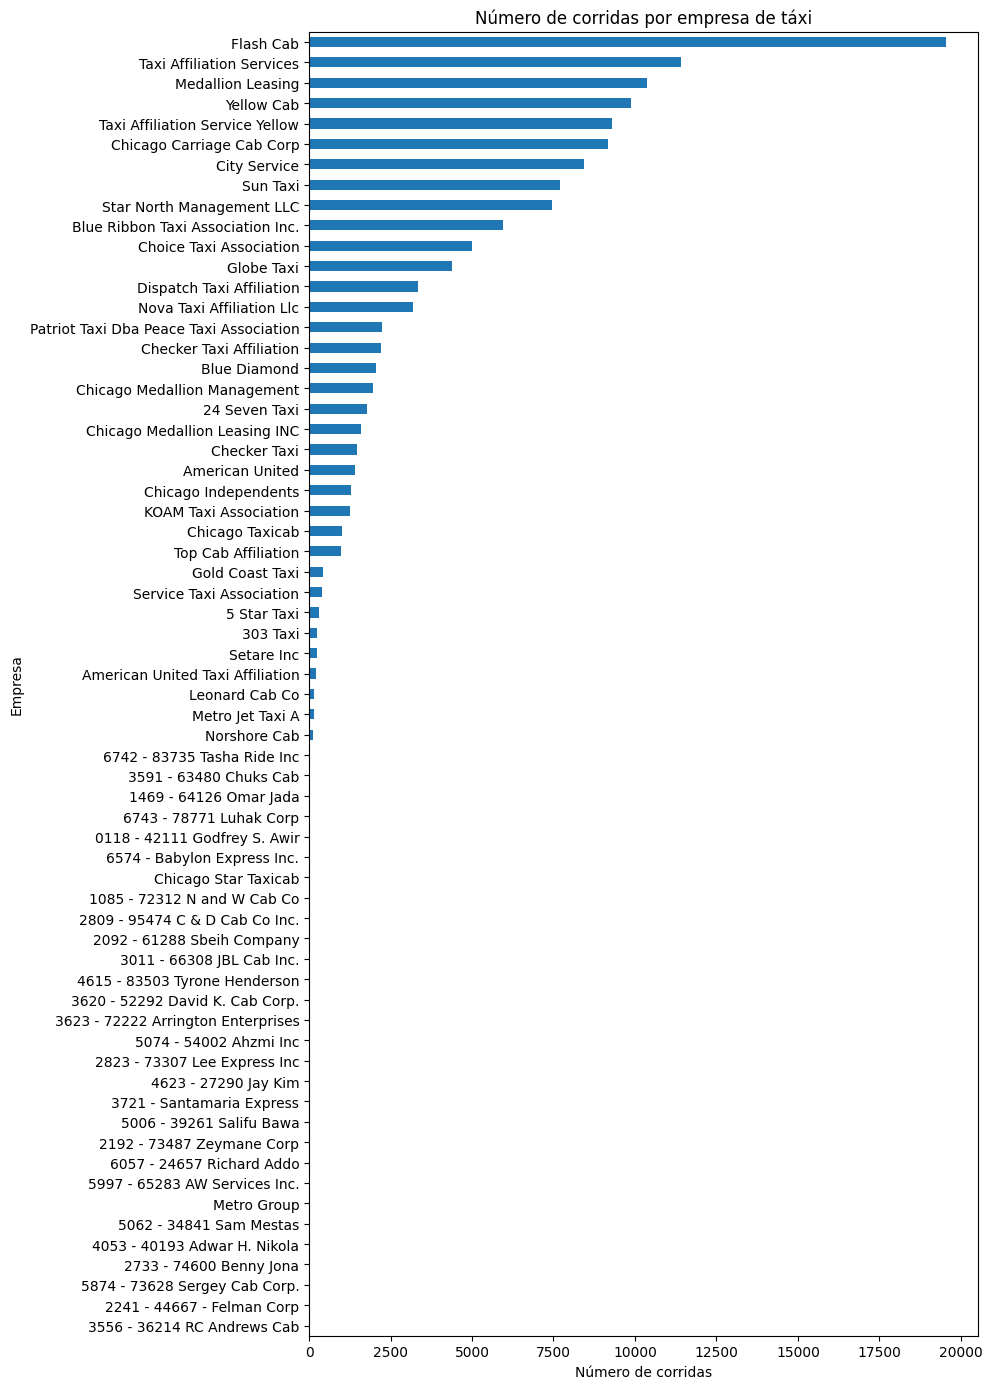

In [13]:
company_sorted = df_company.sort_values(
    by='trips_amount',
    ascending=True
)

ax = company_sorted.plot(
    x='company_name',
    y='trips_amount',
    kind='barh',
    figsize=(10, 14),
    legend=False
)
ax.set_title('Número de corridas por empresa de táxi')
ax.set_xlabel('Número de corridas')
ax.set_ylabel('Empresa')
plt.tight_layout()
plt.show()


<div class="alert alert-block alert-success">
O gráfico de barras horizontais é uma boa escolha para 64 empresas. Todos os nomes estão legíveis, sem sobreposição, e o título e os rótulos dos eixos estão presentes. Ele mostra claramente a Flash Cab bem à frente e a longa cauda de empresas com pouquíssimas viagens.
</div>

#### Interpretação do gráfico
Podemos observar que a distribuição das corridas é bastante desigual entre as empresas de táxi. A Flash Cab apresenta o maior número de corridas, ultrapassando significativamente as demais empresas. Em seguida aparecem Taxi Affiliation Services, Medallion Leasing, Yellow Cab e Taxi Affiliation Service Yellow, que também registram volumes elevados de viagens.

Após as empresas líderes, verifica-se uma redução gradual no número de corridas, seguida por uma longa cauda composta por empresas com participação muito menor no mercado. Isso indica que uma pequena quantidade de empresas concentra grande parte das corridas realizadas em Chicago durante o período analisado.

#### Conclusão da análise das empresas de táxi
O mercado de táxis em Chicago apresenta uma forte concentração de corridas em um número reduzido de empresas. A Flash Cab lidera com ampla vantagem, seguida por Taxi Affiliation Services e outras empresas de grande porte.

Ao mesmo tempo, observa-se a existência de diversas empresas com volumes relativamente baixos de corridas, sugerindo uma estrutura de mercado em que poucos participantes dominam a maior parte da procura. Para uma nova empresa como a Zuber, compreender a estratégia e a presença dessas empresas líderes pode ser fundamental para competir de forma eficaz.

### Top 10 empresas de táxi por número de corridas
Como forma de melhorar a interpretação e tornar o resultado do gráfico anterior mais legível, faremos um segundo gráfico.

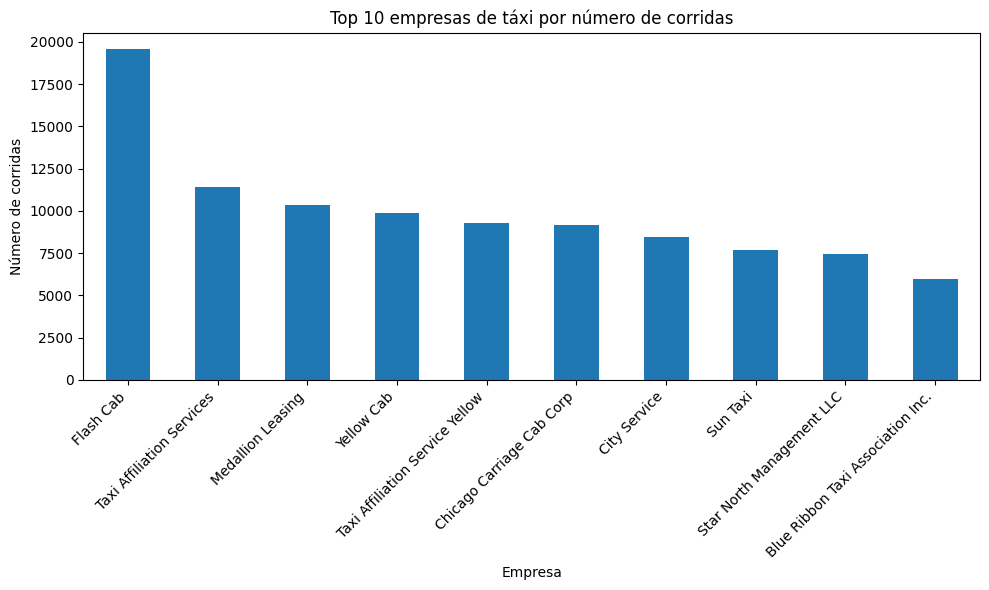

In [14]:
top_10_companies = df_company.sort_values(
    by='trips_amount',
    ascending=False
).head(10)

ax = top_10_companies.plot(
    x='company_name',
    y='trips_amount',
    kind='bar',
    figsize=(10, 6),
    legend=False
)
ax.set_title('Top 10 empresas de táxi por número de corridas')
ax.set_xlabel('Empresa')
ax.set_ylabel('Número de corridas')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


<div class="alert alert-block alert-success">
O gráfico dos 10 principais é um complemento útil ao gráfico completo. Ele deixa a diferença entre a Flash Cab e as demais fácil de enxergar. O título e os rótulos estão presentes, e a rotação dos rótulos mantém legíveis os nomes longos das empresas.
</div>

#### Interpretação do gráfico

O gráfico das dez principais empresas de táxi mostra que a Flash Cab lidera o mercado com uma vantagem significativa sobre os demais concorrentes. A empresa registra quase o dobro de corridas em comparação com várias das empresas que aparecem nas posições seguintes.

Observa-se também que Taxi Affiliation Services, Medallion Leasing, Yellow Cab e Taxi Affiliation Service Yellow apresentam volumes de corridas relativamente próximos, formando um grupo de empresas com forte presença no mercado.

Além disso, a diferença entre as empresas da segunda à décima posição é menor do que a diferença observada entre a Flash Cab e as demais, indicando que a Flash Cab ocupa uma posição de destaque no período analisado.

#### Conclusão da análise das empresas de táxi

Os dados mostram que o mercado de táxis em Chicago é dominado por um pequeno grupo de empresas. A Flash Cab destaca-se como líder absoluta em número de corridas, enquanto Taxi Affiliation Services, Medallion Leasing e Yellow Cab também apresentam participação relevante.

A elevada concentração de corridas entre as principais empresas sugere um mercado competitivo, mas com alguns participantes claramente estabelecidos. Para a Zuber, compreender o posicionamento dessas empresas pode ser importante para identificar oportunidades de entrada e diferenciação no mercado.

<div class="alert alert-block alert-warning">
Esta conclusão repete quase palavra por palavra a que foi colocada antes do gráfico dos top 10, e tem o mesmo título. Mantenha apenas uma delas, de preferência esta, já que ela vem depois do gráfico dos top 10. Você também poderia reforçar a afirmação de que poucas empresas dominam com um número. Por exemplo, a participação das 10 principais no total de viagens: `top_10_companies['trips_amount'].sum() / df_company['trips_amount'].sum()`. Isso é opcional.
</div>

### Top 10 bairros por número médio de corridas em que esse bairro é destino

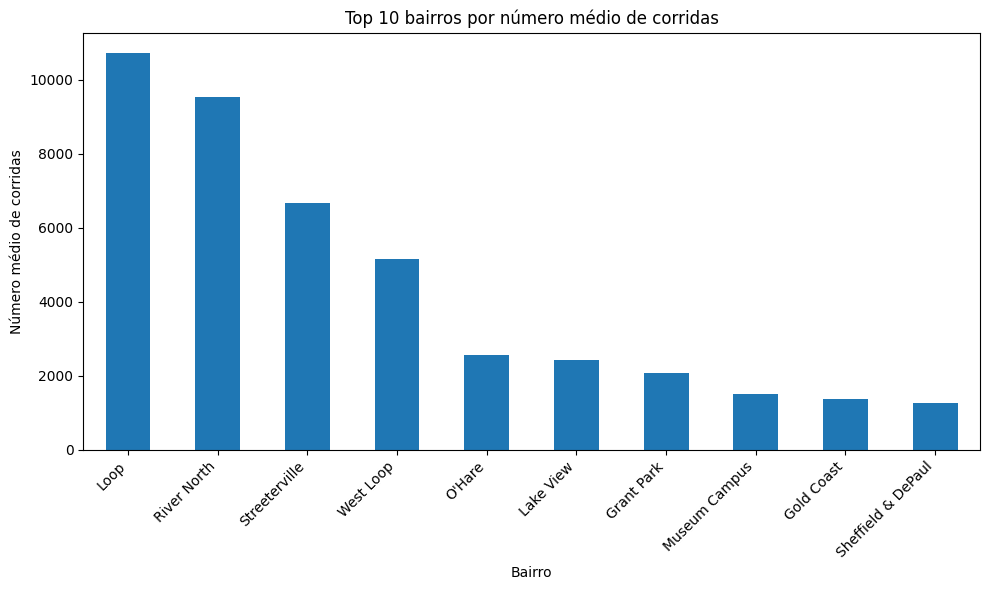

In [15]:
ax = top_10_neighborhoods.plot(
    x='dropoff_location_name',
    y='average_trips',
    kind='bar',
    figsize=(10, 6),
    legend=False
)
ax.set_title('Top 10 bairros por número médio de corridas')
ax.set_xlabel('Bairro')
ax.set_ylabel('Número médio de corridas')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()



<div class="alert alert-block alert-success">
O gráfico de bairros está correto e fácil de ler. Ele mostra os 10 principais destinos em ordem decrescente, de Loop (cerca de 10,7 mil) a Sheffield & DePaul (cerca de 1,3 mil). O título, os rótulos dos eixos e os nomes rotacionados estão todos no lugar.
</div>

#### Interpretação do gráfico


O gráfico mostra os dez bairros com maior número médio de corridas que terminaram nesses locais durante novembro de 2017.

O bairro **Loop** destaca-se como o principal destino, com mais de 10 mil corridas em média, seguido por River North com aproximadamente 9,5 mil corridas. Ambos apresentam valores significativamente superiores aos demais bairros analisados.

Streeterville e West Loop ocupam a terceira e quarta posições, mantendo um volume elevado de corridas, embora inferior aos dois primeiros colocados.

Observa-se uma queda acentuada a partir da quinta posição, ocupada por O'Hare, indicando que os quatro primeiros bairros concentram uma parcela considerável dos destinos das corridas.

Os demais bairros do Top 10 apresentam volumes mais modestos, mas continuam representando áreas importantes de movimentação de passageiros na cidade.

#### Conclusão da análise dos bairros de destino

As corridas de táxi que terminaram em novembro de 2017 concentraram-se sobretudo em alguns bairros. Loop e River North apresentaram as maiores médias diárias, seguidos por Streeterville e West Loop. A posição destes bairros pode estar relacionada com a concentração de atividades comerciais, empresariais e turísticas, embora esta análise, por si só, não permita confirmar as causas.

O Aeroporto Internacional O'Hare também aparece entre os dez principais destinos, evidenciando a relevância das deslocações relacionadas com o transporte aéreo. Estes resultados podem ajudar a identificar áreas com maior procura, sem implicar que o mesmo padrão se mantenha noutros períodos.

## Teste de Hipóteses (Python)

### SQL 4 — Identificadores dos bairros Loop e O'Hare

A consulta recupera os identificadores necessários para filtrar as viagens. Os IDs usados na consulta final são Loop = 50 e O'Hare = 63.

```sql
SELECT
    neighborhood_id,
    name
FROM neighborhoods
WHERE name IN ('O''Hare', 'Loop');
```

<div class="alert alert-block alert-success">
Sua consulta SQL 4 recupera corretamente `neighborhood_id` e `name` para Loop e O'Hare. O apóstrofo em `'O''Hare'` está escapado corretamente. Você também informa os IDs resultantes (50 e 63) e os relaciona com a consulta final.
</div>

### SQL 5 — Classificação horária das condições meteorológicas

A consulta usa CASE para classificar como Bad as descrições que contêm rain ou storm, e como Good as restantes. A saída inclui o timestamp ts e a coluna weather_conditions.

```sql
SELECT
    ts,
    CASE
        WHEN description LIKE '%rain%'
          OR description LIKE '%storm%'
        THEN 'Bad'
        ELSE 'Good'
    END AS weather_conditions
FROM weather_records;
```

<div class="alert alert-block alert-success">
Sua consulta SQL 5 está correta. O `CASE` com `LIKE '%rain%' OR LIKE '%storm%'` rotula essas horas como "Bad" e todas as outras como "Good". A saída tem exatamente os dois campos necessários, `ts` e `weather_conditions`.
</div>

### SQL 6 — Viagens de sábado entre Loop e O'Hare com condições meteorológicas

A consulta associa cada viagem ao registo meteorológico do mesmo timestamp. O INNER JOIN exclui viagens sem registo meteorológico correspondente. A saída corresponde a project_sql_result_07.csv e contém start_ts, weather_conditions e duration_seconds.

```sql
SELECT
    trips.start_ts,
    CASE
        WHEN weather_records.description LIKE '%rain%'
          OR weather_records.description LIKE '%storm%'
        THEN 'Bad'
        ELSE 'Good'
    END AS weather_conditions,
    trips.duration_seconds
FROM trips
INNER JOIN weather_records
    ON trips.start_ts = weather_records.ts
WHERE trips.pickup_location_id = 50
  AND trips.dropoff_location_id = 63
  AND EXTRACT(DOW FROM trips.start_ts) = 6
ORDER BY trips.trip_id;
```

<div class="alert alert-block alert-success">
Sua consulta SQL 6 está bem construída. Ela usa um `INNER JOIN` no timestamp, então as viagens sem dados de clima são descartadas. Ela filtra o embarque 50 e o desembarque 63, seleciona os sábados com `EXTRACT(DOW ...) = 6` e retorna o horário de início, a condição climática e a duração.
</div>

### Teste de hipóteses (Python)
O ficheiro **project_sql_result_07.csv** é carregado abaixo. Antes de comparar as durações dos grupos Good e Bad, verificaremos tipos de dados, valores ausentes, duplicados e durações suspeitas.

In [16]:
df_weather = pd.read_csv('/datasets/project_sql_result_07.csv')

print('Dimensão do conjunto de dados:', df_weather.shape)
display(df_weather.head())
df_weather.info()

Dimensão do conjunto de dados: (1068, 3)


,start_ts,weather_conditions,duration_seconds
0,2017-11-25 16:00:00,Good,2410.0
1,2017-11-25 14:00:00,Good,1920.0
2,2017-11-25 12:00:00,Good,1543.0
3,2017-11-04 10:00:00,Good,2512.0
4,2017-11-11 07:00:00,Good,1440.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1068 entries, 0 to 1067
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   start_ts            1068 non-null   object 
 1   weather_conditions  1068 non-null   object 
 2   duration_seconds    1068 non-null   float64
dtypes: float64(1), object(2)
memory usage: 25.2+ KB


### Preparação dos dados para o teste de hipótese

Nesta etapa, será verificada a estrutura do conjunto de dados utilizado para o teste de hipótese. Também será realizada a conversão da coluna de datas para o formato datetime, facilitando possíveis análises temporais.

### Verificação de valores ausentes, duplicados e durações suspeitas
A verificação de duplicados e valores ausentes permite avaliar a qualidade do ficheiro. Também identificamos durações iguais ou inferiores a zero, que não são plausíveis para uma viagem entre Loop e O'Hare. Valores elevados serão investigados, mas não removidos automaticamente apenas por serem extremos.

In [17]:
print('Valores ausentes por coluna:')
display(df_weather.isna().sum())

print('Linhas duplicadas:', df_weather.duplicated().sum())

print('Registos com duração igual ou inferior a zero:')
display(df_weather[df_weather['duration_seconds'] <= 0])

print('Estatísticas iniciais da duração:')
display(df_weather['duration_seconds'].describe())


Valores ausentes por coluna:


start_ts              0
weather_conditions    0
duration_seconds      0
dtype: int64

Linhas duplicadas: 197
Registos com duração igual ou inferior a zero:


,start_ts,weather_conditions,duration_seconds
163,2017-11-11 09:00:00,Good,0.0
168,2017-11-11 07:00:00,Good,0.0
204,2017-11-18 19:00:00,Good,0.0
552,2017-11-04 01:00:00,Good,0.0
801,2017-11-04 09:00:00,Good,0.0
1063,2017-11-25 11:00:00,Good,0.0


Estatísticas iniciais da duração:


count    1068.000000
mean     2071.731273
std       769.461125
min         0.000000
25%      1438.250000
50%      1980.000000
75%      2580.000000
max      7440.000000
Name: duration_seconds, dtype: float64

In [18]:
# Excluir apenas linhas sem dados essenciais ou com duração não positiva.
essential_columns = ['start_ts', 'weather_conditions', 'duration_seconds']
missing_essential = df_weather[essential_columns].isna().any(axis=1)
nonpositive_duration = df_weather['duration_seconds'].notna() & (df_weather['duration_seconds'] <= 0)

print('Linhas com algum valor essencial ausente:', int(missing_essential.sum()))
print('Linhas com duração <= 0:', int(nonpositive_duration.sum()))

df_weather_valid = df_weather.loc[
    ~missing_essential & df_weather['duration_seconds'].gt(0)
].copy()
df_weather_valid['start_ts'] = pd.to_datetime(df_weather_valid['start_ts'])

print('Registos originais:', len(df_weather))
print('Registos válidos para o teste:', len(df_weather_valid))
print('Registos excluídos:', len(df_weather) - len(df_weather_valid))
df_weather_valid.info()


Linhas com algum valor essencial ausente: 0
Linhas com duração <= 0: 6
Registos originais: 1068
Registos válidos para o teste: 1062
Registos excluídos: 6
<class 'pandas.core.frame.DataFrame'>
Int64Index: 1062 entries, 0 to 1067
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   start_ts            1062 non-null   datetime64[ns]
 1   weather_conditions  1062 non-null   object        
 2   duration_seconds    1062 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 33.2+ KB


<div class="alert alert-block alert-success">
Esta é uma etapa de limpeza cuidadosa. Você remove apenas as 6 linhas com duração zero e imprime as contagens antes e depois (de 1068 para 1062). Você também usa `.copy()` e converte a coluna de data para datetime após a filtragem.
</div>

#### Decisão sobre linhas duplicadas
Foram identificadas 197 linhas exatamente duplicadas. Como o ficheiro não contém um identificador único de viagem e os horários estão arredondados à hora, não é possível concluir que estas linhas sejam erros: podem representar viagens diferentes com os mesmos valores registados. Por isso, mantemos as linhas duplicadas na análise principal e verificamos se a conclusão se altera quando são removidas numa análise de sensibilidade.

### Investigação de durações longas
Uma duração de 7.440 segundos equivale a 124 minutos. O critério do intervalo interquartil (IQR) ajuda a identificar valores elevados para inspeção, mas não prova que sejam erros. Por isso, durações positivas longas serão mantidas, salvo evidência concreta de erro no registo.

In [19]:
q1 = df_weather_valid['duration_seconds'].quantile(0.25)
q3 = df_weather_valid['duration_seconds'].quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr

long_duration_rows = df_weather_valid[
    df_weather_valid['duration_seconds'] > upper_fence
].sort_values('duration_seconds', ascending=False)

print(f'Limite superior IQR: {upper_fence:.1f} segundos')
print('Número de durações acima do limite IQR:', len(long_duration_rows))
display(long_duration_rows.head(10))


Limite superior IQR: 4290.0 segundos
Número de durações acima do limite IQR: 6


,start_ts,weather_conditions,duration_seconds
354,2017-11-25 11:00:00,Good,7440.0
619,2017-11-25 14:00:00,Good,6420.0
276,2017-11-18 12:00:00,Bad,4980.0
583,2017-11-11 16:00:00,Good,4980.0
79,2017-11-11 15:00:00,Good,4800.0
646,2017-11-11 13:00:00,Good,4380.0


<div class="alert alert-block alert-success">
A verificação do IQR está correta (limite superior de 4290 s). Listar os 6 valores acima dele permite que o leitor avalie se são plausíveis. Sua decisão de manter as durações longas, a menos que haja evidência de erro, é sensata.
</div>

**Decisão**: excluímos durações iguais ou inferiores a zero por serem incompatíveis com uma viagem real. Mantemos durações longas positivas porque um valor extremo, isoladamente, não comprova erro; removê-las sem evidência poderia distorcer a amostra.

In [20]:
df_weather_valid['weather_conditions'].value_counts()


Good    882
Bad     180
Name: weather_conditions, dtype: int64

<div class="alert alert-block alert-warning">
Este `value_counts()` repete a saída que você imprime novamente em uma célula posterior, logo antes do teste de hipótese. Remova um dos dois. Como alternativa, transforme este em uma breve nota sobre o tamanho dos grupos (882 Good vs. 180 Bad), já que o desbalanceamento é o motivo pelo qual o teste de Welch é uma escolha sensata. Isso é opcional.
</div>

In [21]:
good_weather = df_weather_valid.loc[
    df_weather_valid['weather_conditions'] == 'Good',
    'duration_seconds'
]

bad_weather = df_weather_valid.loc[
    df_weather_valid['weather_conditions'] == 'Bad',
    'duration_seconds'
]


In [22]:
# Ver estatísticas básicas
print('Clima bom:')
print(good_weather.describe())

print()

print('Clima ruim:')
print(bad_weather.describe())

Clima bom:
count     882.000000
mean     2013.278912
std       743.565217
min        60.000000
25%      1397.250000
50%      1800.000000
75%      2460.000000
max      7440.000000
Name: duration_seconds, dtype: float64

Clima ruim:
count     180.000000
mean     2427.205556
std       721.314138
min       480.000000
25%      1962.000000
50%      2540.000000
75%      2928.000000
max      4980.000000
Name: duration_seconds, dtype: float64


In [26]:
# Verificar viagens muito curtas no grupo Good (menos de 5 minutos)
short_good = df_weather_valid[
    (df_weather_valid['weather_conditions'] == 'Good')
    & (df_weather_valid['duration_seconds'] < 300)
]
print('Viagens Good com menos de 5 minutos:', len(short_good))
display(short_good.head(10))

# Análise de sensibilidade: excluir viagens Good com menos de 5 minutos
good_weather_no_short = df_weather_valid.loc[
    (df_weather_valid['weather_conditions'] == 'Good')
    & (df_weather_valid['duration_seconds'] >= 300),
    'duration_seconds'
]
bad_weather_for_sensitivity = df_weather_valid.loc[
    df_weather_valid['weather_conditions'] == 'Bad',
    'duration_seconds'
]
sensitivity_short = stats.ttest_ind(
    good_weather_no_short,
    bad_weather_for_sensitivity,
    equal_var=False
)
print(f'p-value sem viagens Good < 5 min: {sensitivity_short.pvalue:.6g}')
print(f'Média Good sem viagens < 5 min: {good_weather_no_short.mean():.2f} s')
print(f'Média Bad: {bad_weather_for_sensitivity.mean():.2f} s')


Viagens Good com menos de 5 minutos: 1


,start_ts,weather_conditions,duration_seconds
15,2017-11-25 13:00:00,Good,60.0


p-value sem viagens Good < 5 min: 2.97276e-11
Média Good sem viagens < 5 min: 2015.50 s
Média Bad: 2427.21 s


<div class="alert alert-block alert-warning">
A verificação de sensibilidade é uma ótima adição. Você encontrou exatamente uma viagem Good de 60 s e executou o teste novamente sem ela, e o p-valor permanece em torno de 3e-11, então a conclusão é robusta. A variável `bad_weather_for_sensitivity` é uma cópia exata da variável `bad_weather` que você já criou, então você pode reutilizar `bad_weather` e remover o código duplicado. Isso é opcional.
</div>

### Formulação de Hipóteses

#### Hipótese Nula ($H_o$)
A duração média das corridas do Loop para o Aeroporto Internacional O'Hare é a mesma em sábados com clima bom e em sábados com clima ruim.

<div class="alert alert-block alert-success">
Suas hipóteses estão claras e limitadas à rota do Loop até O'Hare aos sábados. A hipótese nula afirma que a duração média é a mesma com bom e mau tempo, e a alternativa afirma que ela é diferente. A forma bilateral corresponde à pergunta sobre se a duração muda nos sábados chuvosos.
</div>

#### Hipótese Alternativa ($H_1$)
A duração média das corridas do Loop para o Aeroporto Internacional O'Hare é diferente em sábados com clima bom e em sábados com clima ruim.

#### Nível de significância
Adotamos  $\alpha = 0{,}05$ (5%). Neste problema, isso corresponde a aceitar um risco de 5% de rejeitar a hipótese nula quando as durações médias dos grupos Good e Bad não diferem realmente. É um compromisso razoável entre exigir evidência estatística forte e manter capacidade para detetar uma diferença potencialmente relevante para o planeamento operacional. O nível é definido antes de observar o resultado do teste.

<div class="alert alert-block alert-warning">
Sua explicação do nível de significância de 5% no contexto deste problema está boa. Um pequeno ponto: você diz que o nível é definido "antes de observar o resultado do teste", mas um teste de sensibilidade anterior já exibiu um valor-p. Considere uma redação mais flexível, por exemplo "adotamos 5% como o limiar de decisão para o teste principal", ou coloque esta seção antes de qualquer teste ser executado. Isso é opcional.
</div>

In [23]:
df_weather_valid['weather_conditions'].value_counts()


Good    882
Bad     180
Name: weather_conditions, dtype: int64

In [24]:
print(f'Média - Good: {good_weather.mean():.2f} segundos')
print(f'Média - Bad: {bad_weather.mean():.2f} segundos')
print(f'Diferença entre as médias: {bad_weather.mean() - good_weather.mean():.2f} segundos')


Média - Good: 2013.28 segundos
Média - Bad: 2427.21 segundos
Diferença entre as médias: 413.93 segundos


### Teste de Hipótese
Como estamos comparando as médias de dois grupos independentes ("Good" e "Bad"), o teste adequado é o teste t para duas amostras independentes (ttest_ind).

Será utilizada a opção equal_var=False (teste de Welch), que não assume variâncias iguais entre os grupos e é considerada uma abordagem mais robusta quando essa condição não pode ser garantida.

<div class="alert alert-block alert-success">
Você justifica bem o teste. Dois grupos independentes exigem um teste t para amostras independentes. Você explica que `equal_var=False` (Welch) é mais robusto porque não se pode assumir variâncias iguais. Isso responde claramente qual critério você usou e por quê.
</div>

In [25]:
alpha = 0.05

results = stats.ttest_ind(
    good_weather,
    bad_weather,
    equal_var=False
)

print(f'p-value: {results.pvalue:.6g}')
print(f'Nível de significância (alpha): {alpha}')

if results.pvalue < alpha:
    print('Rejeitamos a hipótese nula: há evidência de diferença entre as durações médias.')
else:
    print('Não rejeitamos a hipótese nula: não há evidência suficiente de diferença entre as durações médias.')


p-value: 2.41736e-11
Nível de significância (alpha): 0.05
Rejeitamos a hipótese nula: há evidência de diferença entre as durações médias.


<div class="alert alert-block alert-success">
O teste foi implementado corretamente. Você compara o p-valor (cerca de 2.42e-11) com `alpha` e imprime uma decisão clara de rejeitar a hipótese nula. A decisão corresponde à saída.
</div>

In [27]:
# Análise de sensibilidade: comparar o teste com e sem linhas exatamente duplicadas
df_no_duplicates = df_weather_valid.drop_duplicates().copy()
good_no_duplicates = df_no_duplicates.loc[
    df_no_duplicates['weather_conditions'] == 'Good', 'duration_seconds'
]
bad_no_duplicates = df_no_duplicates.loc[
    df_no_duplicates['weather_conditions'] == 'Bad', 'duration_seconds'
]
results_no_duplicates = stats.ttest_ind(
    good_no_duplicates, bad_no_duplicates, equal_var=False
)

print('Com duplicados — p-value:', f'{results.pvalue:.6g}')
print('Sem duplicados — p-value:', f'{results_no_duplicates.pvalue:.6g}')
print(f'Média Good sem duplicados: {good_no_duplicates.mean():.2f} s')
print(f'Média Bad sem duplicados: {bad_no_duplicates.mean():.2f} s')


Com duplicados — p-value: 2.41736e-11
Sem duplicados — p-value: 2.8592e-07
Média Good sem duplicados: 2049.26 s
Média Bad sem duplicados: 2409.23 s


<div class="alert alert-block alert-success">
A verificação sem linhas duplicadas é uma adição sólida. O p-value continua bem abaixo de 0,05 (cerca de 2,86e-07), e as médias mantêm a mesma direção (cerca de 2.049 s para Good e 2.409 s para Bad). Isso mostra que seu resultado não depende da forma como as duplicatas são tratadas.
</div>

#### Resultados do teste estatístico

Resultados do teste estatístico
O teste t de Welch apresentou um valor-p de aproximadamente $2,42 \times 10 ^ {-11}$, inferior ao nível de significância de $ \alpha = 0,05 $. Assim, rejeitamos a hipótese nula de igualdade das durações médias.

A duração média foi de 2.013,28 segundos (33,6 minutos) em condições Good e de 2.427,21 segundos (40,5 minutos) em condições Bad. A diferença foi de aproximadamente 413,93 segundos (6,9 minutos), com viagens mais longas no grupo Bad.

Este resultado indica uma associação estatisticamente significativa entre a classificação meteorológica e a duração média das viagens de sábado entre Loop e O'Hare. Não demonstra, por si só, causalidade, pois outros fatores — como trânsito e hora do dia — também podem influenciar a duração.

<div class="alert alert-block alert-warning">
Seu resumo informa o valor-p, as duas médias, a diferença (cerca de 413,93 s, ou 6,9 min) e a direção. O cuidado em relação à diferença entre associação e causalidade está bem colocado. Duas pequenas melhorias: primeiro, o título "Resultados do teste estatístico" aparece duas vezes seguidas, então remova a linha repetida. Segundo, acrescente uma frase com os resultados das suas duas verificações de robustez (sem duplicatas e sem a viagem Good de 60 segundos) e diga que a conclusão não muda. Ambas são opcionais.
</div>

## Conclusão Geral
Neste projeto, analisámos dados do serviço de táxis de Chicago para identificar empresas com maior volume de corridas, os bairros que registaram mais destinos e a relação entre as condições meteorológicas e a duração das viagens. Os dados meteorológicos de novembro de 2017 foram obtidos por web scraping com requests e BeautifulSoup. As consultas SQL documentam a preparação dos conjuntos de dados usados na análise Python.

1. #### Análise das empresas de táxi
   
Nas corridas de 15 e 16 de novembro de 2017, a Flash Cab apresentou o maior número de viagens, com 19.558, seguida pela Taxi Affiliation Services, com 11.422, e pela Medallion Leasing, com 10.367. O gráfico das dez principais empresas confirma a posição de destaque da Flash Cab e mostra que o volume de corridas se distribui de forma desigual entre os operadores.

2. #### Análise dos bairros de destino

Em novembro de 2017, Loop apresentou a maior média diária de corridas terminadas no bairro, com aproximadamente 10.727, seguido por River North (cerca de 9.524) e Streeterville (cerca de 6.665). West Loop também apresentou um volume elevado, e O'Hare ocupou a quinta posição, com aproximadamente 2.547. A liderança de Loop e River North pode estar relacionada com a atividade comercial, profissional e turística dessas áreas, mas os dados analisados não permitem confirmar essas causas.

3. #### Teste de hipótese sobre as condições meteorológicas
   
Foram comparadas as durações das viagens de sábado entre Loop e o Aeroporto Internacional O'Hare nos grupos Good e Bad, usando o teste t de Welch para duas amostras independentes e um nível de significância de 0,05 ($\alpha = 0,05$).

O conjunto tinha 1.068 registos. Foram removidas seis viagens com duração igual a zero, incompatíveis com uma duração real de viagem, ficando 1.062 registos para a análise principal. As durações positivas longas foram mantidas, porque um valor extremo, por si só, não comprova erro. Foram identificadas 197 linhas exatamente duplicadas; como o ficheiro não contém um identificador único de viagem e os horários são arredondados à hora, estas linhas foram mantidas na análise principal, pois podem corresponder a viagens distintas com valores coincidentes. Uma análise de sensibilidade compara também os resultados sem duplicados e sem viagens Good inferiores a cinco minutos.

O teste t de Welch apresentou um valor-p de aproximadamente $2,42 \times 10^{-11}$, inferior a 0,05, pelo que rejeitamos a hipótese nula de igualdade das médias. A duração média foi de 2.013,28 segundos (33,6 minutos) em condições Good e de 2.427,21 segundos (40,5 minutos) em condições Bad: uma diferença de aproximadamente 413,93 segundos (6,9 minutos), com viagens mais longas no grupo Bad.

O resultado indica uma associação estatisticamente significativa entre a classificação meteorológica e a duração média das viagens analisadas, mas não prova que o mau tempo seja a única causa das viagens mais longas. Trânsito, hora do dia e outros fatores também podem influenciar os tempos de deslocação.

4. #### Implicações para a Zuber
   
A análise identifica concorrentes com grande volume de viagens, bairros que concentram destinos e uma diferença nas durações médias associada às condições meteorológicas. Estes resultados podem apoiar o planeamento operacional da Zuber, nomeadamente na identificação de áreas com elevada procura e na consideração de possíveis variações nos tempos de viagem em condições meteorológicas adversas.

<div class="alert alert-block alert-success">
Sua conclusão geral está de acordo com a sua análise. Os números das empresas, as médias por bairro, os detalhes dos testes e as decisões de limpeza de dados estão todos corretos. A linguagem cautelosa em relação à causalidade é uma ótima forma de encerrar o projeto. Como um toque opcional, a seção sobre as implicações para a Zuber poderia incluir uma conclusão concreta baseada nos dados, por exemplo, que as viagens nesse trajeto duraram cerca de 7 minutos a mais, em média, em condições de chuva ou tempestade.
</div>